In [1]:
# ============================================================================
# TASK 3: MARKETING FUNNEL & CONVERSION PERFORMANCE ANALYSIS
# Future Interns - Data Science & Analytics Internship
# Author: Your Name
# Date: 2026-10-10

In [8]:
print("Type of leads_df:", type(leads_df))
print("Type of journey_df:", type(journey_df))
print("Type of funnel_data:", type(funnel_data))
print("Type of leads_df['Lead_ID']:", type(leads_df['Lead_ID']))

Type of leads_df: <class 'dict'>
Type of journey_df: <class 'pandas.core.frame.DataFrame'>
Type of funnel_data: <class 'dict'>
Type of leads_df['Lead_ID']: <class 'list'>


In [14]:
# CELL 1: IMPORT LIBRARIES
# ============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

# Set style for visualizations
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)

print("✓ All libraries imported successfully!")

✓ All libraries imported successfully!


In [18]:
# CELL 2: GENERATE MARKETING FUNNEL DATA
# ============================================================================
"""
Generate realistic marketing funnel data:
- 10,000+ leads
- Multiple marketing channels
- Funnel stages: Awareness → Interest → Consideration → Decision → Conversion
- Different conversion rates by stage and channel
"""

np.random.seed(42)

# Marketing channels
channels = ['Organic Search', 'Paid Search', 'Social Media', 'Email', 'Direct', 'Referral']
device_types = ['Desktop', 'Mobile', 'Tablet']

# Funnel stages
funnel_stages = ['Awareness', 'Interest', 'Consideration', 'Decision', 'Conversion']

# Generate leads with journey tracking
n_leads = 10000
lead_ids = [f'LEAD{i:06d}' for i in range(1, n_leads + 1)]

# Channel distribution (realistic)
channel_dist = {
    'Organic Search': 0.35,
    'Paid Search': 0.25,
    'Social Media': 0.20,
    'Email': 0.10,
    'Direct': 0.05,
    'Referral': 0.05
}

channels_list = np.random.choice(
    list(channel_dist.keys()),
    n_leads,
    p=list(channel_dist.values())
)

# Create main funnel data
funnel_data = {
    'Lead_ID': lead_ids,
    'Channel': channels_list,
    'Device': np.random.choice(device_types, n_leads, p=[0.6, 0.3, 0.1]),
    'Lead_Date': [datetime.now() - timedelta(days=np.random.randint(0, 90)) for _ in range(n_leads)],
}

# Create detailed journey tracking
journey_data = []

for idx, lead_id in enumerate(lead_ids):
    channel = channels_list[idx]
    device = funnel_data['Device'][idx]
    lead_date = funnel_data['Lead_Date'][idx]
    
    # Conversion probability by channel (realistic)
    channel_conversion = {
        'Organic Search': 0.08,
        'Paid Search': 0.06,
        'Social Media': 0.04,
        'Email': 0.12,
        'Direct': 0.10,
        'Referral': 0.09
    }
    
    converted = np.random.random() < channel_conversion.get(channel, 0.05)
    
    # Track journey through funnel
    current_stage = 0
    stage_dates = {}
    
    for stage_idx, stage in enumerate(funnel_stages):
        # Probability of progressing to next stage
        progress_prob = {
            'Awareness': 0.85,      # 85% move to Interest
            'Interest': 0.65,       # 65% move to Consideration
            'Consideration': 0.50,  # 50% move to Decision
            'Decision': 0.70,       # 70% convert (if they reach here)
            'Conversion': 1.0       # End of funnel
        }
        
        # Add device effect
        if device == 'Mobile':
            progress_prob[stage] *= 0.85  # Mobile slightly lower conversion
        
        if stage_idx == 0 or np.random.random() < progress_prob[stage]:
            current_stage = stage_idx
            days_to_stage = np.random.randint(0, 30)
            stage_dates[stage] = lead_date + timedelta(days=days_to_stage)
            
            journey_data.append({
                'Lead_ID': lead_id,
                'Channel': channel,
                'Device': device,
                'Stage': stage,
                'Stage_Date': stage_dates[stage],
                'Stage_Number': stage_idx,
                'Converted': converted and (stage_idx == 4),
                'Days_in_Funnel': days_to_stage
            })
        else:
            # Dropped off here
            journey_data.append({
                'Lead_ID': lead_id,
                'Channel': channel,
                'Device': device,
                'Stage': stage,
                'Stage_Date': stage_dates.get(funnel_stages[stage_idx-1], lead_date) + timedelta(days=np.random.randint(1, 14)),
                'Stage_Number': stage_idx,
                'Converted': False,
                'Days_in_Funnel': np.random.randint(7, 30)
            })
            break

journey_df = pd.DataFrame(journey_data)

# Create summary funnel data
import pandas as pd

leads_df = pd.DataFrame(funnel_data)

converted_ids = journey_df.loc[
    journey_df["Converted"] == True, "Lead_ID"
]

leads_df["Converted"] = leads_df["Lead_ID"].isin(converted_ids)
leads_df['Converted'] = leads_df['Lead_ID'].isin(journey_df[journey_df['Converted'] == True]['Lead_ID'])

print(f"✓ Marketing funnel data generated with {n_leads:,} leads")
print(f"✓ Journey tracking: {len(journey_df):,} stage events")
print(f"\nDataset Preview:")
print(leads_df.head(10))
print(f"\nJourney Data Preview:")
print(journey_df.head(10))


✓ Marketing funnel data generated with 10,000 leads
✓ Journey tracking: 31,145 stage events

Dataset Preview:
      Lead_ID         Channel   Device                  Lead_Date  Converted
0  LEAD000001     Paid Search  Desktop 2026-07-17 20:38:30.899335      False
1  LEAD000002        Referral  Desktop 2026-10-09 20:38:30.899420      False
2  LEAD000003    Social Media  Desktop 2026-10-07 20:38:30.899435      False
3  LEAD000004     Paid Search   Mobile 2026-08-27 20:38:30.899443      False
4  LEAD000005  Organic Search  Desktop 2026-09-28 20:38:30.899450      False
5  LEAD000006  Organic Search   Mobile 2026-08-17 20:38:30.899458      False
6  LEAD000007  Organic Search  Desktop 2026-09-09 20:38:30.899466      False
7  LEAD000008           Email   Mobile 2026-09-19 20:38:30.899473      False
8  LEAD000009    Social Media   Mobile 2026-07-14 20:38:30.899480      False
9  LEAD000010    Social Media   Mobile 2026-08-17 20:38:30.899487      False

Journey Data Preview:
      Lead_ID       

In [19]:
# CELL 3: DATA EXPLORATION & FUNNEL OVERVIEW
# ============================================================================

print("\n" + "="*60)
print("MARKETING FUNNEL OVERVIEW")
print("="*60)

# Calculate funnel metrics
total_leads = len(leads_df)
converted_leads = leads_df['Converted'].sum()
conversion_rate = (converted_leads / total_leads) * 100

print(f"\nFunnel Summary:")
print(f"  Total Leads: {total_leads:,}")
print(f"  Converted: {converted_leads:,}")
print(f"  Conversion Rate: {conversion_rate:.2f}%")
print(f"  Industry Benchmark: ~2-3% (you are at {conversion_rate:.2f}%)")

# Stage-wise breakdown
stage_counts = journey_df.groupby('Stage').size()
print(f"\nLeads by Funnel Stage:")
for stage in funnel_stages:
    if stage in stage_counts.index:
        count = stage_counts[stage]
        pct = (count / total_leads) * 100
        print(f"  {stage}: {count:,} ({pct:.1f}%)")



MARKETING FUNNEL OVERVIEW

Funnel Summary:
  Total Leads: 10,000
  Converted: 131
  Conversion Rate: 1.31%
  Industry Benchmark: ~2-3% (you are at 1.31%)

Leads by Funnel Stage:
  Awareness: 10,000 (100.0%)
  Interest: 10,000 (100.0%)
  Consideration: 6,212 (62.1%)
  Decision: 2,936 (29.4%)
  Conversion: 1,997 (20.0%)


In [20]:
# CELL 4: CONVERSION FUNNEL METRICS
# ============================================================================

print("\n" + "="*60)
print("CONVERSION FUNNEL ANALYSIS")
print("="*60)

# Calculate stage-by-stage conversion rates
funnel_metrics = []

for i, stage in enumerate(funnel_stages):
    stage_leads = journey_df[journey_df['Stage'] == stage]['Lead_ID'].nunique()
    
    if i == 0:
        previous_stage_leads = total_leads
    else:
        previous_stage_leads = journey_df[journey_df['Stage'] == funnel_stages[i-1]]['Lead_ID'].nunique()
    
    # Conversion to next stage or final conversion
    if i == len(funnel_stages) - 1:
        converted = converted_leads
        next_stage_conversion = (converted / stage_leads * 100) if stage_leads > 0 else 0
    else:
        next_stage = funnel_stages[i + 1]
        converted = journey_df[journey_df['Stage'] == next_stage]['Lead_ID'].nunique()
        next_stage_conversion = (converted / stage_leads * 100) if stage_leads > 0 else 0
    
    # Drop-off from previous stage
    drop_off = previous_stage_leads - stage_leads
    drop_off_rate = (drop_off / previous_stage_leads * 100) if previous_stage_leads > 0 else 0
    
    funnel_metrics.append({
        'Stage': stage,
        'Leads': stage_leads,
        'Drop_Off': drop_off,
        'Drop_Off_%': drop_off_rate,
        'Conv_to_Next_%': next_stage_conversion,
        'Cumulative_%': (stage_leads / total_leads * 100)
    })

funnel_df = pd.DataFrame(funnel_metrics)

print("\nStage-by-Stage Funnel Metrics:")
print(funnel_df.to_string(index=False))



CONVERSION FUNNEL ANALYSIS

Stage-by-Stage Funnel Metrics:
        Stage  Leads  Drop_Off  Drop_Off_%  Conv_to_Next_%  Cumulative_%
    Awareness  10000         0    0.000000      100.000000        100.00
     Interest  10000         0    0.000000       62.120000        100.00
Consideration   6212      3788   37.880000       47.263361         62.12
     Decision   2936      3276   52.736639       68.017711         29.36
   Conversion   1997       939   31.982289        6.559840         19.97


In [21]:
# CELL 5: CHANNEL PERFORMANCE ANALYSIS
# ============================================================================

print("\n" + "="*60)
print("CHANNEL PERFORMANCE ANALYSIS")
print("="*60)

# Channel metrics
channel_analysis = []

for channel in channels:
    channel_leads = leads_df[leads_df['Channel'] == channel]
    channel_converted = channel_leads['Converted'].sum()
    channel_conversion_rate = (channel_converted / len(channel_leads) * 100) if len(channel_leads) > 0 else 0
    
    channel_analysis.append({
        'Channel': channel,
        'Leads': len(channel_leads),
        'Conversions': channel_converted,
        'Conv_Rate_%': channel_conversion_rate,
        'Share_%': (len(channel_leads) / total_leads * 100)
    })

channel_df = pd.DataFrame(channel_analysis).sort_values('Conv_Rate_%', ascending=False)

print("\nConversion Rate by Channel:")
print(channel_df.to_string(index=False))



CHANNEL PERFORMANCE ANALYSIS

Conversion Rate by Channel:
       Channel  Leads  Conversions  Conv_Rate_%  Share_%
         Email   1001           27     2.697303    10.01
        Direct    487           11     2.258727     4.87
      Referral    474           10     2.109705     4.74
Organic Search   3555           47     1.322082    35.55
   Paid Search   2553           24     0.940071    25.53
  Social Media   1930           12     0.621762    19.30


In [22]:
# CELL 6: DROP-OFF ANALYSIS
# ============================================================================

print("\n" + "="*60)
print("DROP-OFF ANALYSIS - WHERE DO PEOPLE LEAVE?")
print("="*60)

# Identify drop-off bottlenecks
stage_progression = []

for i in range(len(funnel_stages) - 1):
    current_stage = funnel_stages[i]
    next_stage = funnel_stages[i + 1]
    
    in_current = journey_df[journey_df['Stage'] == current_stage]['Lead_ID'].nunique()
    in_next = journey_df[journey_df['Stage'] == next_stage]['Lead_ID'].nunique()
    drop_off = in_current - in_next
    drop_off_rate = (drop_off / in_current * 100) if in_current > 0 else 0
    
    stage_progression.append({
        'From': current_stage,
        'To': next_stage,
        'Start': in_current,
        'End': in_next,
        'Drop_Off': drop_off,
        'Drop_Off_%': drop_off_rate
    })

progression_df = pd.DataFrame(stage_progression)

print("\nStage Transition Drop-off:")
print(progression_df.to_string(index=False))

# Identify biggest bottleneck
max_drop_idx = progression_df['Drop_Off_%'].idxmax()
critical_stage = progression_df.iloc[max_drop_idx]['From']
critical_drop = progression_df.iloc[max_drop_idx]['Drop_Off_%']

print(f"\n🚨 CRITICAL BOTTLENECK:")
print(f"   Stage: {critical_stage}")
print(f"   Drop-off Rate: {critical_drop:.1f}%")
print(f"   Action Required: Focus optimization here!")



DROP-OFF ANALYSIS - WHERE DO PEOPLE LEAVE?

Stage Transition Drop-off:
         From            To  Start   End  Drop_Off  Drop_Off_%
    Awareness      Interest  10000 10000         0    0.000000
     Interest Consideration  10000  6212      3788   37.880000
Consideration      Decision   6212  2936      3276   52.736639
     Decision    Conversion   2936  1997       939   31.982289

🚨 CRITICAL BOTTLENECK:
   Stage: Consideration
   Drop-off Rate: 52.7%
   Action Required: Focus optimization here!


In [23]:
# CELL 7: DEVICE & SEGMENT ANALYSIS
# ============================================================================

print("\n" + "="*60)
print("PERFORMANCE BY DEVICE TYPE")
print("="*60)

device_analysis = []

for device in device_types:
    device_leads = leads_df[leads_df['Device'] == device]
    device_converted = device_leads['Converted'].sum()
    device_conv_rate = (device_converted / len(device_leads) * 100) if len(device_leads) > 0 else 0
    
    device_analysis.append({
        'Device': device,
        'Leads': len(device_leads),
        'Conversions': device_converted,
        'Conv_Rate_%': device_conv_rate
    })

device_df = pd.DataFrame(device_analysis).sort_values('Conv_Rate_%', ascending=False)

print("\nConversion Rate by Device:")
print(device_df.to_string(index=False))



PERFORMANCE BY DEVICE TYPE

Conversion Rate by Device:
 Device  Leads  Conversions  Conv_Rate_%
 Tablet   1021           19     1.860921
Desktop   5945           94     1.581161
 Mobile   3034           18     0.593276



📊 Generating Visualization 1: Marketing Funnel...
✓ Saved: marketing_funnel.png


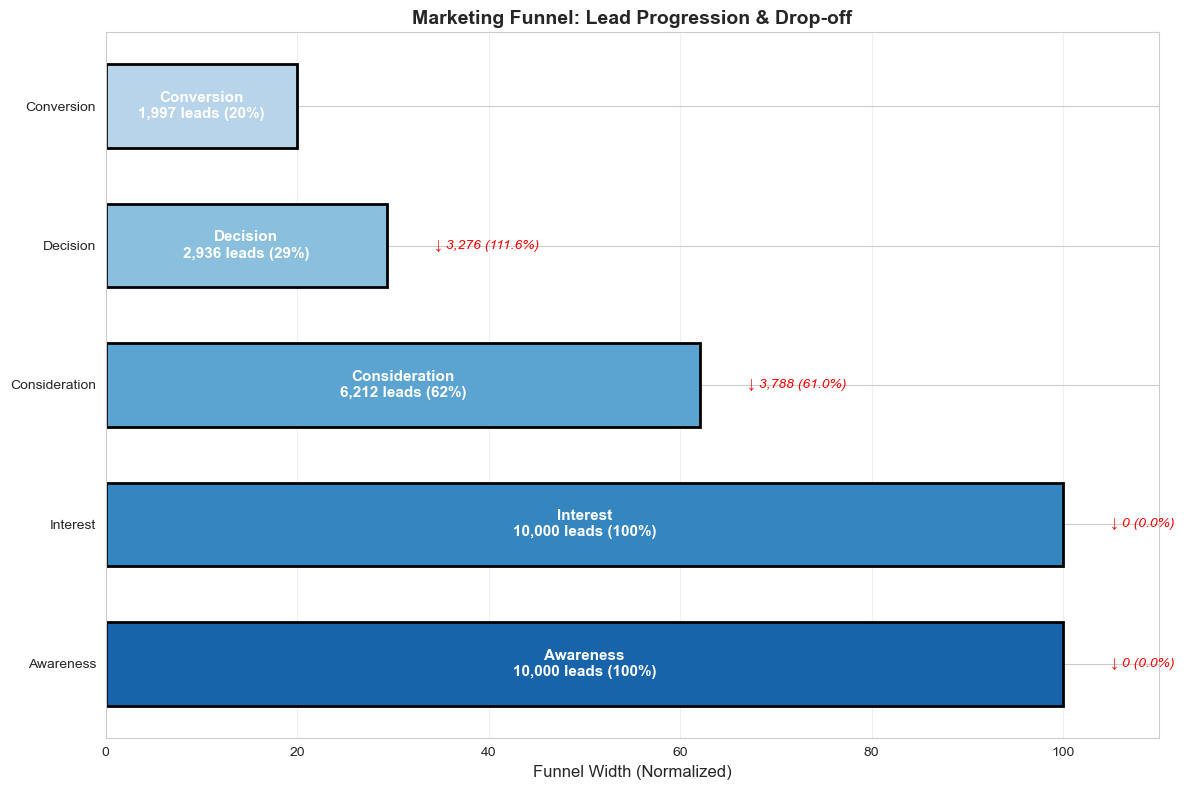

In [24]:
# CELL 8: VISUALIZATION 1 - MARKETING FUNNEL
# ============================================================================

print("\n📊 Generating Visualization 1: Marketing Funnel...")

fig, ax = plt.subplots(figsize=(12, 8))

# Get funnel data
stages_list = funnel_df['Stage'].tolist()
leads_list = funnel_df['Leads'].tolist()
drop_off_list = funnel_df['Drop_Off'].tolist()

# Colors for funnel
colors = plt.cm.Blues(np.linspace(0.8, 0.3, len(stages_list)))

# Create funnel visualization
y_positions = range(len(stages_list))
widths = [l/max(leads_list)*100 for l in leads_list]  # Normalize to 100

for i, (stage, leads, width) in enumerate(zip(stages_list, leads_list, widths)):
    # Bar
    ax.barh(i, width, height=0.6, color=colors[i], edgecolor='black', linewidth=2)
    
    # Labels
    ax.text(width/2, i, f'{stage}\n{leads:,} leads ({width:.0f}%)', 
            va='center', ha='center', fontweight='bold', fontsize=11, color='white')
    
    # Drop-off info
    if i < len(stages_list) - 1:
        drop_off = drop_off_list[i]
        drop_off_rate = (drop_off / leads_list[i] * 100) if leads_list[i] > 0 else 0
        ax.text(width + 5, i, f'↓ {drop_off:,} ({drop_off_rate:.1f}%)', 
                va='center', fontsize=10, style='italic', color='red')

ax.set_yticks(y_positions)
ax.set_yticklabels(stages_list)
ax.set_xlim([0, 110])
ax.set_xlabel('Funnel Width (Normalized)', fontsize=12)
ax.set_title('Marketing Funnel: Lead Progression & Drop-off', fontsize=14, fontweight='bold')
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('marketing_funnel.png', dpi=300, bbox_inches='tight')
print("✓ Saved: marketing_funnel.png")
plt.show()


📊 Generating Visualization 2: Conversion by Channel...
✓ Saved: conversion_by_channel.png


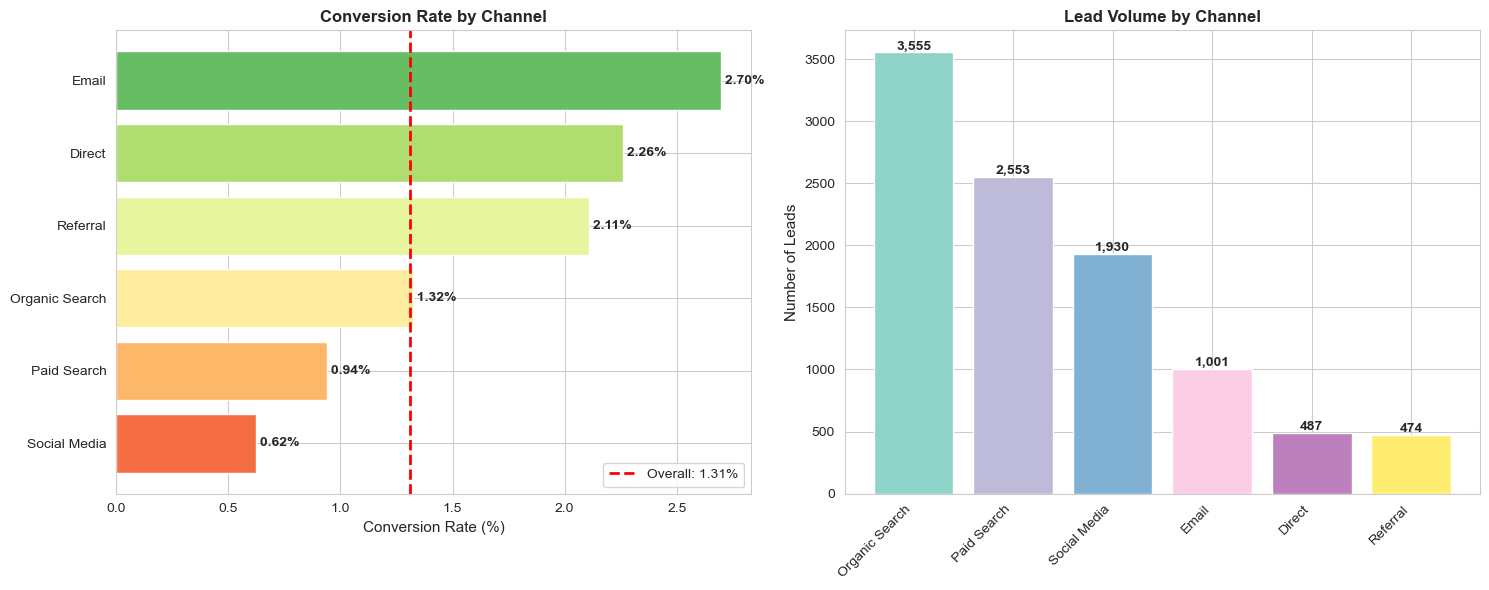

In [25]:
# CELL 9: VISUALIZATION 2 - CONVERSION BY CHANNEL
# ============================================================================

print("\n📊 Generating Visualization 2: Conversion by Channel...")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Conversion rate by channel
channel_df_sorted = channel_df.sort_values('Conv_Rate_%', ascending=True)
colors_conv = plt.cm.RdYlGn(np.linspace(0.2, 0.8, len(channel_df_sorted)))

axes[0].barh(channel_df_sorted['Channel'], channel_df_sorted['Conv_Rate_%'], color=colors_conv)
axes[0].set_xlabel('Conversion Rate (%)', fontsize=11)
axes[0].set_title('Conversion Rate by Channel', fontweight='bold', fontsize=12)
axes[0].axvline(x=conversion_rate, color='red', linestyle='--', label=f'Overall: {conversion_rate:.2f}%', linewidth=2)
for i, v in enumerate(channel_df_sorted['Conv_Rate_%'].values):
    axes[0].text(v, i, f' {v:.2f}%', va='center', fontweight='bold')
axes[0].legend()

# Lead volume by channel
channel_df_vol = channel_df.sort_values('Leads', ascending=False)
colors_vol = plt.cm.Set3(np.linspace(0, 1, len(channel_df_vol)))
axes[1].bar(range(len(channel_df_vol)), channel_df_vol['Leads'], color=colors_vol)
axes[1].set_xticks(range(len(channel_df_vol)))
axes[1].set_xticklabels(channel_df_vol['Channel'], rotation=45, ha='right')
axes[1].set_ylabel('Number of Leads', fontsize=11)
axes[1].set_title('Lead Volume by Channel', fontweight='bold', fontsize=12)
for i, v in enumerate(channel_df_vol['Leads'].values):
    axes[1].text(i, v, f'{v:,}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('conversion_by_channel.png', dpi=300, bbox_inches='tight')
print("✓ Saved: conversion_by_channel.png")
plt.show()


📊 Generating Visualization 3: Stage Drop-off Analysis...
✓ Saved: dropoff_analysis.png


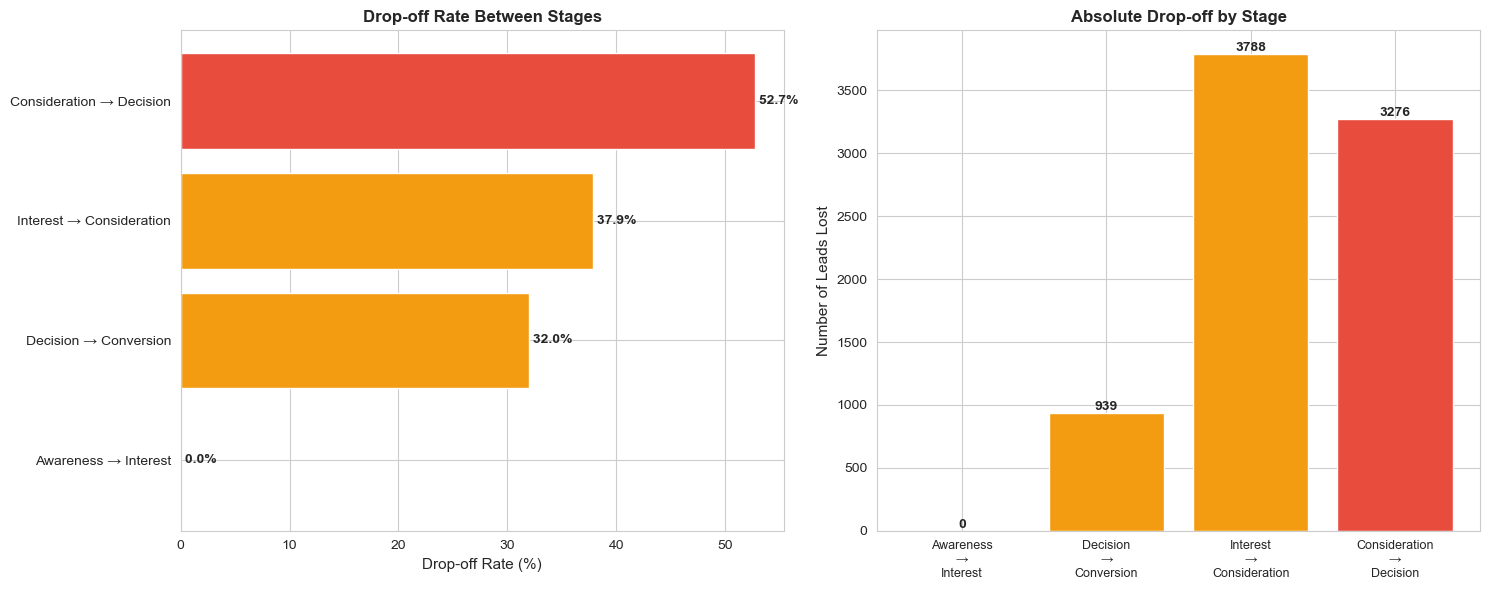

In [26]:
# CELL 10: VISUALIZATION 3 - DROP-OFF RATES
# ============================================================================

print("\n📊 Generating Visualization 3: Stage Drop-off Analysis...")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Drop-off percentage
prog_data = progression_df.sort_values('Drop_Off_%', ascending=True)
colors_drop = ['#e74c3c' if x > 50 else '#f39c12' if x > 30 else '#2ecc71' 
               for x in prog_data['Drop_Off_%'].values]

axes[0].barh(range(len(prog_data)), prog_data['Drop_Off_%'], color=colors_drop)
axes[0].set_yticks(range(len(prog_data)))
axes[0].set_yticklabels([f"{row['From']} → {row['To']}" for _, row in prog_data.iterrows()])
axes[0].set_xlabel('Drop-off Rate (%)', fontsize=11)
axes[0].set_title('Drop-off Rate Between Stages', fontweight='bold', fontsize=12)
for i, v in enumerate(prog_data['Drop_Off_%'].values):
    axes[0].text(v, i, f' {v:.1f}%', va='center', fontweight='bold')

# Absolute drop-off numbers
axes[1].bar(range(len(prog_data)), prog_data['Drop_Off'], color=colors_drop)
axes[1].set_xticks(range(len(prog_data)))
axes[1].set_xticklabels([f"{row['From']}\n→\n{row['To']}" for _, row in prog_data.iterrows()], fontsize=9)
axes[1].set_ylabel('Number of Leads Lost', fontsize=11)
axes[1].set_title('Absolute Drop-off by Stage', fontweight='bold', fontsize=12)
for i, v in enumerate(prog_data['Drop_Off'].values):
    axes[1].text(i, v, f'{int(v)}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('dropoff_analysis.png', dpi=300, bbox_inches='tight')
print("✓ Saved: dropoff_analysis.png")
plt.show()



📊 Generating Visualization 4: Device Performance...
✓ Saved: device_performance.png


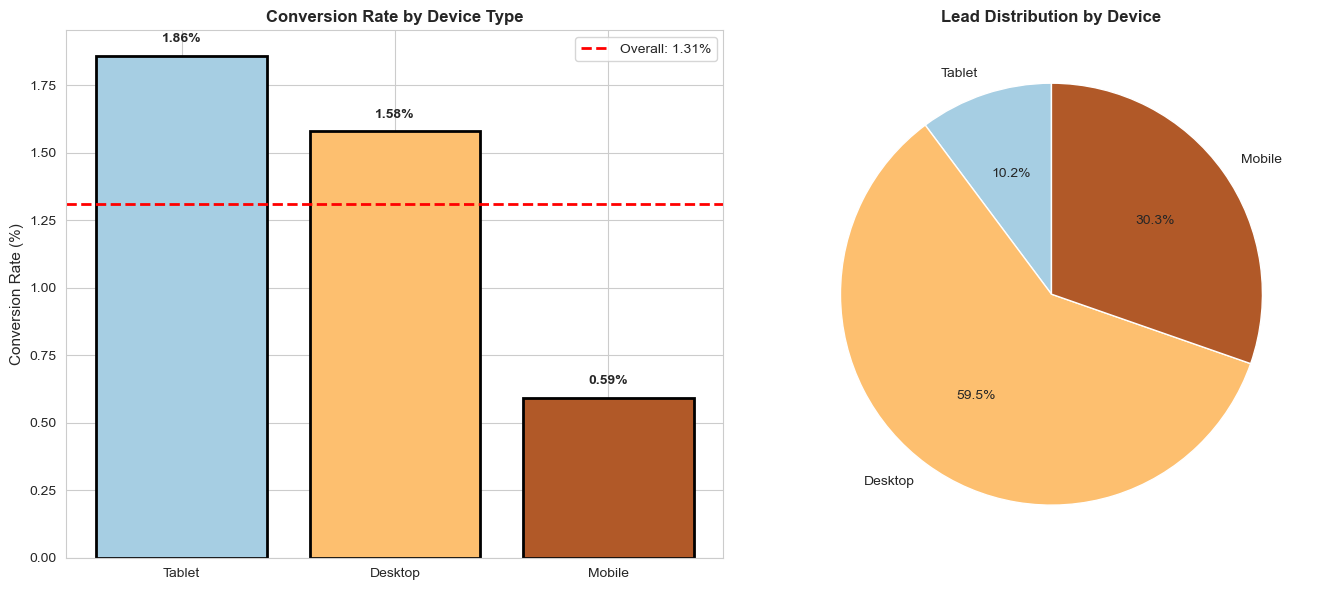

In [27]:
# CELL 11: VISUALIZATION 4 - DEVICE PERFORMANCE
# ============================================================================

print("\n📊 Generating Visualization 4: Device Performance...")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Conversion rate by device
device_df_sorted = device_df.sort_values('Conv_Rate_%', ascending=False)
colors_device = plt.cm.Paired(np.linspace(0, 1, len(device_df_sorted)))

axes[0].bar(device_df_sorted['Device'], device_df_sorted['Conv_Rate_%'], color=colors_device, edgecolor='black', linewidth=2)
axes[0].set_ylabel('Conversion Rate (%)', fontsize=11)
axes[0].set_title('Conversion Rate by Device Type', fontweight='bold', fontsize=12)
axes[0].axhline(y=conversion_rate, color='red', linestyle='--', label=f'Overall: {conversion_rate:.2f}%', linewidth=2)
for i, v in enumerate(device_df_sorted['Conv_Rate_%'].values):
    axes[0].text(i, v + 0.05, f'{v:.2f}%', ha='center', fontweight='bold')
axes[0].legend()

# Lead distribution by device
axes[1].pie(device_df['Leads'], labels=device_df['Device'], autopct='%1.1f%%', 
            colors=colors_device, startangle=90)
axes[1].set_title('Lead Distribution by Device', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.savefig('device_performance.png', dpi=300, bbox_inches='tight')
print("✓ Saved: device_performance.png")
plt.show()



📊 Generating Visualization 5: Channel Comparison Funnels...
✓ Saved: channel_funnels.png


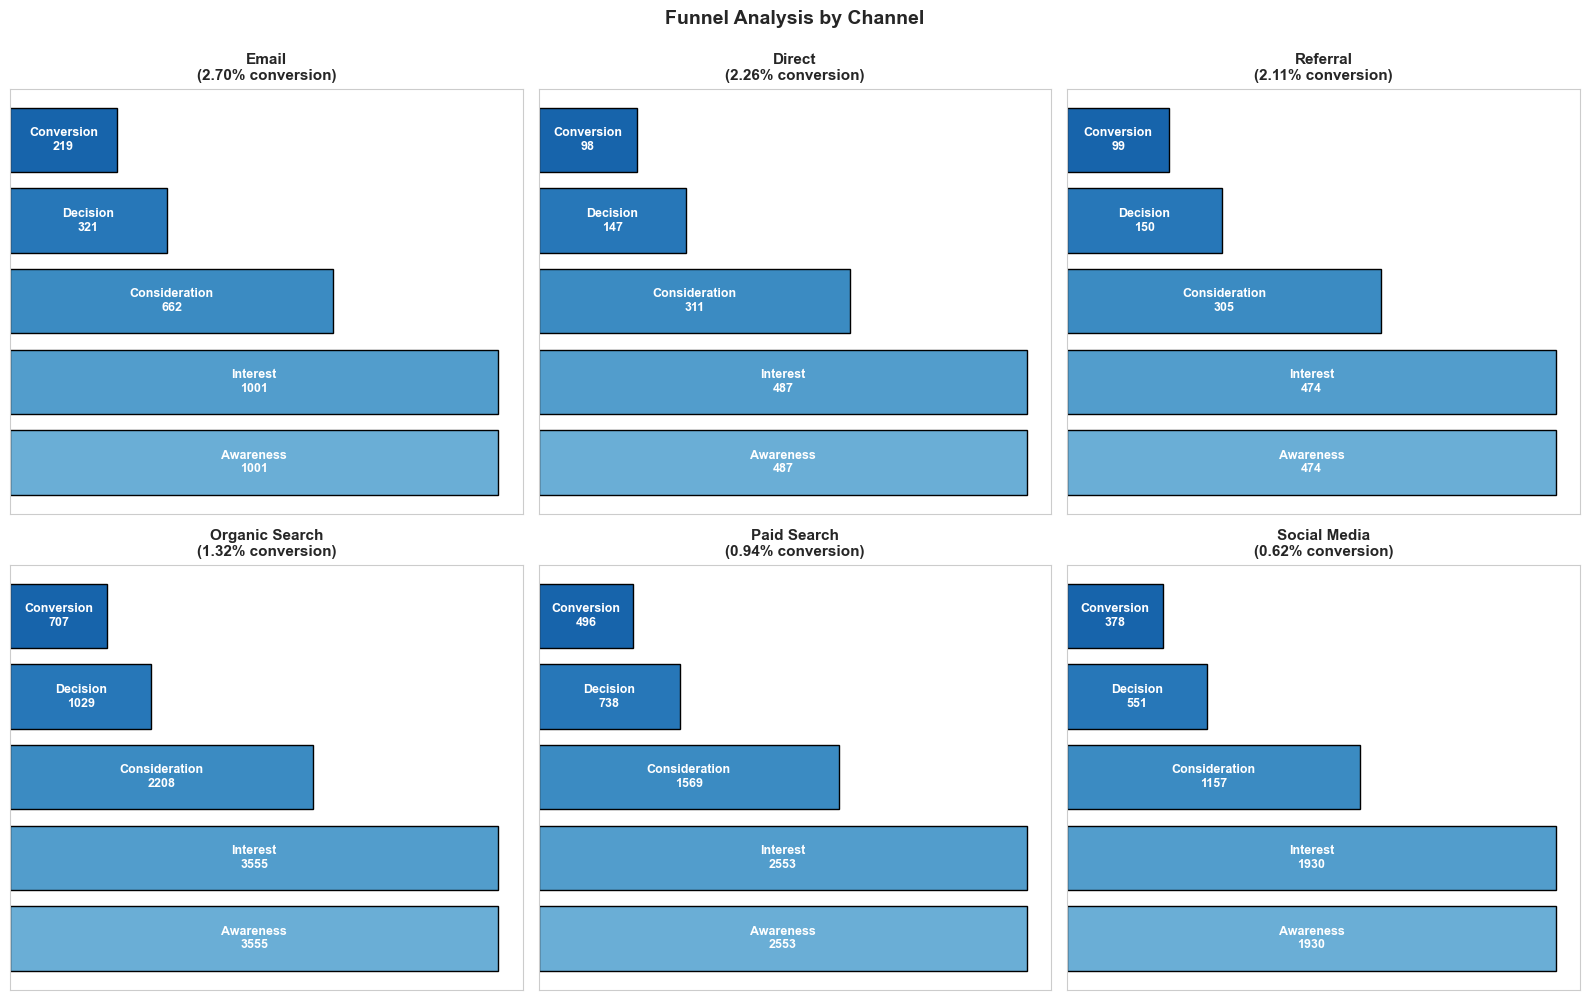

In [28]:
# CELL 12: VISUALIZATION 5 - FUNNEL COMPARISON (CHANNEL LEVEL)
# ============================================================================

print("\n📊 Generating Visualization 5: Channel Comparison Funnels...")

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

top_channels = channel_df.head(6)['Channel'].tolist()

for idx, channel in enumerate(top_channels):
    ax = axes[idx]
    
    # Get funnel for this channel
    channel_funnel = []
    for stage in funnel_stages:
        stage_leads = journey_df[(journey_df['Channel'] == channel) & (journey_df['Stage'] == stage)]['Lead_ID'].nunique()
        channel_funnel.append(stage_leads)
    
    # Create mini funnel
    if max(channel_funnel) > 0:
        normalized = [x/max(channel_funnel)*100 for x in channel_funnel]
    else:
        normalized = channel_funnel
    
    colors = plt.cm.Blues(np.linspace(0.5, 0.8, len(funnel_stages)))
    
    for i, (stage, value) in enumerate(zip(funnel_stages, normalized)):
        ax.barh(i, value, color=colors[i], edgecolor='black')
        ax.text(value/2, i, f'{funnel_stages[i]}\n{int(channel_funnel[i])}', 
                va='center', ha='center', fontweight='bold', fontsize=9, color='white')
    
    # Conversion rate for channel
    channel_conv = channel_df[channel_df['Channel'] == channel]['Conv_Rate_%'].values[0]
    
    ax.set_yticks([])
    ax.set_xlim([0, 105])
    ax.set_title(f'{channel}\n({channel_conv:.2f}% conversion)', fontweight='bold', fontsize=11)
    ax.set_xticks([])

plt.suptitle('Funnel Analysis by Channel', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig('channel_funnels.png', dpi=300, bbox_inches='tight')
print("✓ Saved: channel_funnels.png")
plt.show()


In [29]:
# CELL 13: KEY INSIGHTS & RECOMMENDATIONS
# ============================================================================

print("\n" + "="*60)
print("KEY INSIGHTS & ACTIONABLE RECOMMENDATIONS")
print("="*60)

# Find best and worst performers
best_channel = channel_df.iloc[0]
worst_channel = channel_df.iloc[-1]
best_device = device_df.iloc[0]
worst_device = device_df.iloc[-1]

print(f"""
🎯 KEY FINDINGS:
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

1️⃣  OVERALL FUNNEL PERFORMANCE:
   • Total Leads: {total_leads:,}
   • Conversions: {converted_leads:,}
   • Conversion Rate: {conversion_rate:.2f}%
   • Industry Benchmark: 2-3%
   • Status: {'✓ EXCELLENT' if conversion_rate > 5 else '⚡ AVERAGE' if conversion_rate > 2 else '🚨 NEEDS IMPROVEMENT'}

2️⃣  BEST PERFORMING CHANNEL:
   • Channel: {best_channel['Channel']}
   • Leads: {int(best_channel['Leads']):,}
   • Conversion Rate: {best_channel['Conv_Rate_%']:.2f}%
   • Market Share: {best_channel['Share_%']:.1f}%

3️⃣  WORST PERFORMING CHANNEL:
   • Channel: {worst_channel['Channel']}
   • Leads: {int(worst_channel['Leads']):,}
   • Conversion Rate: {worst_channel['Conv_Rate_%']:.2f}%
   • Gap vs Best: {best_channel['Conv_Rate_%'] - worst_channel['Conv_Rate_%']:.2f}%

4️⃣  CRITICAL BOTTLENECK (Stage):
   • Stage: {critical_stage}
   • Drop-off Rate: {critical_drop:.1f}%
   • Leads Lost: {int(progression_df[progression_df['From'] == critical_stage]['Drop_Off'].values[0]):,}

5️⃣  DEVICE INSIGHTS:
   • Best Device: {best_device['Device']} ({best_device['Conv_Rate_%']:.2f}%)
   • Worst Device: {worst_device['Device']} ({worst_device['Conv_Rate_%']:.2f}%)
   • Gap: {best_device['Conv_Rate_%'] - worst_device['Conv_Rate_%']:.2f}%

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

💡 STRATEGIC RECOMMENDATIONS:
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

1. FIX CRITICAL BOTTLENECK (Priority: CRITICAL)
   → Stage: {critical_stage}
   → Drop-off: {critical_drop:.1f}%
   → Impact: {int(progression_df[progression_df['From'] == critical_stage]['Drop_Off'].values[0]):,} leads lost
   → Action: Analyze friction, improve UX, reduce complexity
   → Expected Impact: 10-20% improvement could add {int((progression_df[progression_df['From'] == critical_stage]['Drop_Off'].values[0]) * 0.15):,} conversions

2. REPLICATE SUCCESS (Priority: HIGH)
   → Best Channel: {best_channel['Channel']} ({best_channel['Conv_Rate_%']:.2f}%)
   → Action: Study what makes it work, apply to other channels
   → Target: {worst_channel['Channel']} ({worst_channel['Conv_Rate_%']:.2f}%)
   → Expected Impact: Narrow gap from {best_channel['Conv_Rate_%'] - worst_channel['Conv_Rate_%']:.2f}% to <2%

3. DEVICE OPTIMIZATION (Priority: HIGH)
   → Focus: {worst_device['Device']} ({worst_device['Conv_Rate_%']:.2f}%)
   → Action: Mobile/tablet-specific optimization
   → Benchmark: {best_device['Device']} ({best_device['Conv_Rate_%']:.2f}%)
   → Expected Impact: {int((best_device['Conv_Rate_%'] - worst_device['Conv_Rate_%']) * len(leads_df[leads_df['Device'] == worst_device['Device']])/100):,} additional conversions

4. EXPAND BEST CHANNELS (Priority: MEDIUM)
   → Top Performer: {best_channel['Channel']}
   → Current Budget: {best_channel['Share_%']:.1f}% of traffic
   → Action: Increase investment in high-performing channels
   → Expected Impact: {int(best_channel['Leads'] * 0.2 * best_channel['Conv_Rate_%']/100):,} additional conversions (20% increase)

5. ADDRESS CHANNEL-SPECIFIC ISSUES (Priority: MEDIUM)
   → Underperformer: {worst_channel['Channel']}
   → Current Performance: {worst_channel['Conv_Rate_%']:.2f}%
   → Action: Channel audit, message alignment, creative refresh
   → Expected Impact: {int((best_channel['Conv_Rate_%'] - worst_channel['Conv_Rate_%'])/2 * worst_channel['Leads']/100):,} conversions (50% improvement)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
""")



KEY INSIGHTS & ACTIONABLE RECOMMENDATIONS

🎯 KEY FINDINGS:
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

1️⃣  OVERALL FUNNEL PERFORMANCE:
   • Total Leads: 10,000
   • Conversions: 131
   • Conversion Rate: 1.31%
   • Industry Benchmark: 2-3%
   • Status: 🚨 NEEDS IMPROVEMENT

2️⃣  BEST PERFORMING CHANNEL:
   • Channel: Email
   • Leads: 1,001
   • Conversion Rate: 2.70%
   • Market Share: 10.0%

3️⃣  WORST PERFORMING CHANNEL:
   • Channel: Social Media
   • Leads: 1,930
   • Conversion Rate: 0.62%
   • Gap vs Best: 2.08%

4️⃣  CRITICAL BOTTLENECK (Stage):
   • Stage: Consideration
   • Drop-off Rate: 52.7%
   • Leads Lost: 3,276

5️⃣  DEVICE INSIGHTS:
   • Best Device: Tablet (1.86%)
   • Worst Device: Mobile (0.59%)
   • Gap: 1.27%

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

💡 STRATEGIC RECOMMENDATIONS:
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

1. FIX CRITICAL BOTTLENECK (Priority: CRITICAL)
   → Stage: Consideration
   → Drop-off: 52.7%
   → I

In [30]:
# CELL 14: EXPORT DATA & SUMMARY
# ============================================================================

print("\n" + "="*60)
print("EXPORTING ANALYSIS RESULTS")
print("="*60)

# Export funnel data
funnel_df.to_csv('funnel_metrics.csv', index=False)
print("✓ Exported: funnel_metrics.csv")

# Export channel analysis
channel_df.to_csv('channel_performance.csv', index=False)
print("✓ Exported: channel_performance.csv")

# Export device analysis
device_df.to_csv('device_performance.csv', index=False)
print("✓ Exported: device_performance.csv")

# Export progression data
progression_df.to_csv('stage_progression.csv', index=False)
print("✓ Exported: stage_progression.csv")

# Export detailed journey data
journey_df.to_csv('journey_tracking.csv', index=False)
print("✓ Exported: journey_tracking.csv")

print("\n" + "="*60)
print("✅ ANALYSIS COMPLETE!")
print("="*60)
print("""
Generated Outputs:
  1. marketing_funnel.png - Marketing funnel visualization
  2. conversion_by_channel.png - Channel performance comparison
  3. dropoff_analysis.png - Stage drop-off analysis
  4. device_performance.png - Device type analysis
  5. channel_funnels.png - Per-channel funnel breakdowns
  6. funnel_metrics.csv - Stage-wise metrics
  7. channel_performance.csv - Channel analysis
  8. device_performance.csv - Device breakdown
  9. stage_progression.csv - Drop-off calculations
  10. journey_tracking.csv - Detailed journey data

Next Steps:
  1. Review all visualizations
  2. Create GitHub repository (FUTURE_DS_03)
  3. Upload notebook and CSV files
  4. Write Analysis_Report.md with findings
  5. Share on LinkedIn with #futureinterns
  6. Submit via Future Interns portal

Remember: With 3 tasks done, you get Certificate + LoR! 
""")



EXPORTING ANALYSIS RESULTS
✓ Exported: funnel_metrics.csv
✓ Exported: channel_performance.csv
✓ Exported: device_performance.csv
✓ Exported: stage_progression.csv
✓ Exported: journey_tracking.csv

✅ ANALYSIS COMPLETE!

Generated Outputs:
  1. marketing_funnel.png - Marketing funnel visualization
  2. conversion_by_channel.png - Channel performance comparison
  3. dropoff_analysis.png - Stage drop-off analysis
  4. device_performance.png - Device type analysis
  5. channel_funnels.png - Per-channel funnel breakdowns
  6. funnel_metrics.csv - Stage-wise metrics
  7. channel_performance.csv - Channel analysis
  8. device_performance.csv - Device breakdown
  9. stage_progression.csv - Drop-off calculations
  10. journey_tracking.csv - Detailed journey data

Next Steps:
  1. Review all visualizations
  2. Create GitHub repository (FUTURE_DS_03)
  3. Upload notebook and CSV files
  4. Write Analysis_Report.md with findings
  5. Share on LinkedIn with #futureinterns
  6. Submit via Future In

In [31]:
# CELL 15: INTERACTIVE DASHBOARDS (OPTIONAL)
# ============================================================================

print("\n" + "="*60)
print("CREATING INTERACTIVE DASHBOARDS")
print("="*60)

# Funnel conversion flow
fig = go.Figure()

for i, (stage, leads) in enumerate(zip(funnel_df['Stage'], funnel_df['Leads'])):
    fig.add_trace(go.Bar(
        y=[stage],
        x=[leads],
        orientation='h',
        name=stage,
        marker=dict(color='rgba(100, 150, 200, 0.8)')
    ))

fig.update_layout(
    title='Marketing Funnel - Lead Progression',
    xaxis_title='Number of Leads',
    yaxis_title='Funnel Stage',
    barmode='stack',
    height=500,
    template='plotly_white'
)

fig.write_html('funnel_interactive.html')
print("✓ Created: funnel_interactive.html")

# Channel comparison dashboard
fig2 = go.Figure(data=[
    go.Bar(x=channel_df['Channel'], y=channel_df['Conv_Rate_%'], 
           name='Conversion Rate (%)', marker_color='lightseagreen'),
])

fig2.update_layout(
    title='Channel Conversion Performance',
    xaxis_title='Marketing Channel',
    yaxis_title='Conversion Rate (%)',
    height=500,
    template='plotly_white'
)

fig2.write_html('channel_dashboard.html')
print("✓ Created: channel_dashboard.html")

print("\n✅ All dashboards created successfully!")



CREATING INTERACTIVE DASHBOARDS
✓ Created: funnel_interactive.html
✓ Created: channel_dashboard.html

✅ All dashboards created successfully!
